# Topografía de los sitios objetivo y comparación por sitio (v1) · pendiente + relieve local
**NASA Space Apps Challenge 2026** · Amplía `topografia_sitios_v0` con:

1. **Relieve local**: desnivel (máximo − mínimo) en una ventana de ~1,2 km, además de la pendiente. Dos terrenos pueden tener la misma
   pendiente y distinto relieve (llanura con escarpes sueltos frente a lomas continuas).
2. **Tierra completa**: las regiones candidatas medidas enteras en `topografia_v1` (antes, como mucho 6 teselas por región).
3. **Análogos conocidos** (Haughton, Atacama, Craters of the Moon…): se comparan con los sitios igual que las regiones candidatas.
   Sirve para validar el método (¿los análogos que ya usa la NASA se parecen a algún sitio?) y para ver si alguno sirve para Artemis.

| Cuerpo | Sitios (capa `sitios_v0`) | Modelo de elevación | Escala |
|---|---|---|---|
| Luna, al sur de 75° S | 9 regiones Artemis (polígono), IM-1, IM-2, Chang'e 7 | LRO LOLA `LDEM_75S_240M` | 240 m |
| Luna, resto | Apollo y aterrizajes robóticos (radio de 10 km) | LRO LOLA `LDEM_128` | ~237 m |
| Marte | 47 Exploration Zones y aterrizajes (radio de 25 km) | USGS HRSC–MOLA Blended DEM 200 m v2 | 200 m |
| Tierra | regiones candidatas y análogos conocidos | histogramas de `topografia_v1` (ASTER promediado a ~240 m) | ~240 m |

**Comparación**: distancia de Kolmogórov-Smirnov (0 a 1, menor es más parecido) entre las distribuciones de pendiente y entre las de
relieve; la **distancia combinada** es la media de las dos. Se considera «parecido» si la combinada es ≤ 0,2.

**Requisitos**: `topografia_v1` terminado (todas las teselas) y `sitios_objetivo_v0`. Los recortes de la Luna y Marte de
`topografia_sitios_v0` se reutilizan, así que no se vuelve a descargar nada de Marte.

## 0. Instalación

In [9]:
!pip install -q rasterio

## 1. Configuración y funciones comunes

In [10]:
import os, re, json, glob, datetime, unicodedata
import numpy as np, pandas as pd, requests, geopandas as gpd, rasterio
from scipy import ndimage
import matplotlib.pyplot as plt
from rasterio.windows import Window
from pyproj import CRS, Transformer
from shapely import contains_xy
from shapely.geometry import shape
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "topografia_sitios_v1"
RES, WEB = f"{BASE}/04_resultados/{VERSION}", f"{BASE}/06_web/{VERSION}"
CACHE_T = f"{BASE}/03_datos/cache_api/topografia"          # etiqueta de LDEM_128 (de topografia_v0)
CACHE_T1 = f"{BASE}/03_datos/cache_api/topografia_v1"      # histogramas de la Tierra (de topografia_v1)
CACHE = f"{BASE}/03_datos/cache_api/topografia_sitios"     # recortes de LOLA y HRSC (compartidos con v0)
BRUTOS = f"{BASE}/03_datos/brutos/topografia"
for d in (RES, WEB, CACHE, BRUTOS):
    os.makedirs(d, exist_ok=True)

R_LUNA, R_MARTE = 1737400.0, 3396190.0
RADIO_LUNA_KM, RADIO_MARTE_KM = 10, 25          # alrededor de cada punto (en Marte, el centro de la EZ, de 100 km de radio)
PRODUCTO_POLAR = "LDEM_75S_240M"
URL_MARTE = "https://planetarymaps.usgs.gov/mosaic/Mars/HRSC_MOLA_Blend/Mars_HRSC_MOLA_BlendDEM_Global_200mp_v2.tif"
PASO_BIN = 0.25; BINS = np.arange(0, 90 + PASO_BIN, PASO_BIN)
UMBRAL_PARECIDO = 0.2
LADO_RELIEVE_M = 1200                  # igual que en topografia_v1
PASO_REL = 5; BINS_REL = np.arange(0, 3000 + PASO_REL, PASO_REL)

FIGURAS = f"{RES}/figuras"; os.makedirs(FIGURAS, exist_ok=True)
_mostrar = getattr(plt, "_show_original", plt.show); plt._show_original = _mostrar
_n_fig = [0]
def _mostrar_y_guardar(*a, **k):
    fig = plt.gcf()
    if fig.axes:
        _n_fig[0] += 1
        titulo = next((ax.get_title() for ax in fig.axes if ax.get_title()), "figura")
        slug = re.sub(r"[^a-zA-Z0-9]+", "_", unicodedata.normalize("NFKD", titulo).encode("ascii", "ignore").decode()).strip("_").lower()[:50]
        fig.savefig(f"{FIGURAS}/fig_{_n_fig[0]:02d}_{slug}.png", dpi=80, bbox_inches="tight")
    _mostrar(*a, **k)
plt.show = _mostrar_y_guardar

def pendiente(z, dy, dx_filas):
    gy, gx = np.gradient(z)
    return np.degrees(np.arctan(np.hypot(gx / np.asarray(dx_filas)[:, None], gy / dy)))

def estadisticas(h, bins=BINS, umbrales=(5, 10, 15)):
    h = np.asarray(h, float); tot = h.sum()
    if tot == 0:
        return dict(mediana=np.nan, p90=np.nan, **{f"pct_lt{u}": np.nan for u in umbrales})
    acum = np.cumsum(h) / tot
    q = lambda p: float(bins[1:][np.searchsorted(acum, p)])
    paso = bins[1] - bins[0]
    return dict(mediana=q(0.5), p90=q(0.9), **{f"pct_lt{u}": float(acum[int(round(u / paso)) - 1] * 100) for u in umbrales})

def impar(n):
    n = max(int(round(n)), 3)
    return n if n % 2 else n + 1

def relieve(z, dy, dx):
    """Desnivel (máximo − mínimo) en una ventana de ~LADO_RELIEVE_M (misma función que topografia_v1)."""
    tam = (impar(LADO_RELIEVE_M / dy), impar(LADO_RELIEVE_M / dx))
    hueco = ~np.isfinite(z)
    zf = np.where(hueco, np.nanmean(z) if np.isfinite(z).any() else 0, z)
    r = ndimage.maximum_filter(zf, size=tam) - ndimage.minimum_filter(zf, size=tam)
    r[ndimage.maximum_filter(hueco.astype(np.uint8), size=tam) > 0] = np.nan
    return r

def hist_relieve(r, dentro):
    v = r[dentro & np.isfinite(r)]
    return np.histogram(np.clip(v, 0, BINS_REL[-1] - 0.01), BINS_REL)[0]

def histograma(s):
    s = s[np.isfinite(s)]
    return np.histogram(s, BINS)[0], int(s.size)

def circulo(shape_, c_fila, c_col, dy, dx_filas, radio_m):
    yy, xx = np.mgrid[:shape_[0], :shape_[1]]
    return np.hypot((yy - c_fila) * dy, (xx - c_col) * np.asarray(dx_filas)[:, None]) <= radio_m

sitios = gpd.read_file(f"{BASE}/06_web/sitios_v0/sitios.geojson")
polar = gpd.read_file(f"{BASE}/03_datos/procesados/sitios_luna_polar.gpkg")
print(sitios.groupby(["cuerpo", "tipo"]).size())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
cuerpo  tipo                     
luna    aterrizaje_planificado        1
        aterrizaje_robotico          22
        aterrizaje_tripulado          6
        region_aterrizaje_artemis     9
marte   aterrizaje_planificado        1
        aterrizaje_robotico          11
        exploration_zone             47
dtype: int64


## 2. Luna, polo sur: LOLA `LDEM_75S_240M`
Se descarga entero (28 MB, se guarda en `03_datos/brutos/topografia/`). La orientación de la rejilla polar se comprueba
automáticamente comparando con `LDEM_128` en 30 puntos entre 76° S y 84° S: se elige la que da mayor correlación de alturas.

In [11]:
BASES_LOLA = {"polar": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/",
                        "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/POLAR/IMG/",
                        "https://imbrium.mit.edu/DATA/LOLA_GDR/POLAR/IMG/"],
              "cyl": ["https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/cylindrical/img/",
                      "https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/DATA/LOLA_GDR/CYLINDRICAL/IMG/",
                      "https://imbrium.mit.edu/DATA/LOLA_GDR/CYLINDRICAL/IMG/"]}

def campo(txt, k, defecto=None):
    m = re.search(rf"^\s*{k}\s*=\s*\"?([^\s\"<,)]+)", txt, re.M)
    return m.group(1) if m else defecto

def unidad(txt):
    m = re.search(r"^\s*UNIT\s*=\s*\"?([A-Za-z]+)", txt, re.M)
    return m.group(1).upper() if m else None

def etiqueta(producto, tipo, cache_dir):
    """Busca la etiqueta .LBL del producto en PDS (minúsculas o mayúsculas) o en la réplica del MIT; la guarda con la URL del .IMG."""
    ruta, ruta_url = f"{cache_dir}/{producto}.LBL", f"{cache_dir}/{producto}.url"
    if os.path.exists(ruta) and os.path.exists(ruta_url):
        return open(ruta).read(), open(ruta_url).read().strip()
    for b in BASES_LOLA[tipo]:
        for lbl, img in ((producto.lower() + ".lbl", producto.lower() + ".img"), (producto + ".LBL", producto + ".IMG")):
            try:
                r = requests.get(b + lbl, timeout=60)
            except requests.RequestException:
                continue
            if r.status_code == 200 and "LINE_SAMPLES" in r.text:
                open(ruta, "w").write(r.text); open(ruta_url, "w").write(b + img)
                return r.text, b + img
    raise RuntimeError(f"No encuentro {producto}.LBL en PDS ni en imbrium.mit.edu")

def tipo_dato(txt):
    st, bits = campo(txt, "SAMPLE_TYPE", ""), int(campo(txt, "SAMPLE_BITS", "16"))
    orden = "<" if ("LSB" in st or "PC" in st) else ">"
    return np.dtype(f"{orden}f{bits // 8}" if "REAL" in st else f"{orden}i{bits // 8}")

# --- Producto polar ---
LBL_P, URL_P = etiqueta(PRODUCTO_POLAR, "polar", BRUTOS)
RUTA_P = f"{BRUTOS}/{PRODUCTO_POLAR}.IMG"
L_P, S_P = int(campo(LBL_P, "LINES")), int(campo(LBL_P, "LINE_SAMPLES"))
DT_P = tipo_dato(LBL_P)
if not (os.path.exists(RUTA_P) and os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize):
    with requests.get(URL_P, stream=True, timeout=600) as r:
        r.raise_for_status()
        with open(RUTA_P, "wb") as f:
            for t in r.iter_content(1 << 22):
                f.write(t)
assert os.path.getsize(RUTA_P) == L_P * S_P * DT_P.itemsize, "Tamaño del IMG polar distinto del de la etiqueta"
ESCALA_P = float(campo(LBL_P, "MAP_SCALE"))                      # m/píxel
if ESCALA_P < 10: ESCALA_P *= 1000                              # por si viene en km/píxel
L0, S0 = float(campo(LBL_P, "LINE_PROJECTION_OFFSET")), float(campo(LBL_P, "SAMPLE_PROJECTION_OFFSET"))
FACTOR = float(campo(LBL_P, "SCALING_FACTOR", "1"))           # el OFFSET no cambia la pendiente
Z_P = np.memmap(RUTA_P, dtype=DT_P, mode="r", shape=(L_P, S_P))
muestra = np.asarray(Z_P[::max(1, L_P // 50), ::max(1, S_P // 50)], dtype="float64") * FACTOR
EN_KM = unidad(LBL_P) == "KILOMETER" or np.nanmax(np.abs(muestra)) < 30          # alturas en km → se pasan a m
A_METROS = 1000.0 if EN_KM else 1.0
print(f"{PRODUCTO_POLAR}: {L_P}×{S_P} px de {ESCALA_P:.0f} m · {DT_P} · unidad {'km' if EN_KM else 'm'} · {URL_P}")

CRS_SP = CRS.from_proj4(f"+proj=stere +lat_0=-90 +lon_0=0 +k=1 +x_0=0 +y_0=0 +R={R_LUNA} +units=m +no_defs")
GEO_LUNA = CRS.from_proj4(f"+proj=longlat +R={R_LUNA} +no_defs")
a_polar = Transformer.from_crs(GEO_LUNA, CRS_SP, always_xy=True)

def xy_a_pixel(x, y, o):
    sx, sy, cambio = o
    if cambio: x, y = y, x
    return L0 - (sy * y) / ESCALA_P, S0 + (sx * x) / ESCALA_P          # fila, columna (base 0, centro de píxel)

def pixel_a_xy(fila, col, o):
    sx, sy, cambio = o
    x, y = (col - S0) * ESCALA_P / sx, (L0 - fila) * ESCALA_P / sy
    return (y, x) if cambio else (x, y)

def altura_polar(filas, cols):
    f, c = np.round(filas).astype(int), np.round(cols).astype(int)
    ok = (f >= 0) & (f < L_P) & (c >= 0) & (c < S_P)
    out = np.full(f.shape, np.nan)
    out[ok] = np.asarray(Z_P[f[ok], c[ok]], dtype="float64") * FACTOR * A_METROS
    return out

LDEM_75S_240M: 3812×3812 px de 240 m · int16 · unidad m · https://pds-geosciences.wustl.edu/lro/lro-l-lola-3-rdr-v1/lrolol_1xxx/data/lola_gdr/polar/img/ldem_75s_240m.img


In [12]:
# --- LDEM_128 (cilíndrico): lectura por filas, como en topografia_v0 ---
LBL_C, URL_C = etiqueta("LDEM_128", "cyl", CACHE_T)
L_C, S_C, PPD = int(campo(LBL_C, "LINES")), int(campo(LBL_C, "LINE_SAMPLES")), float(campo(LBL_C, "MAP_RESOLUTION"))
DT_C = tipo_dato(LBL_C); FACTOR_C = float(campo(LBL_C, "SCALING_FACTOR", "0.5"))
LATMAX_C, LONW_C = float(campo(LBL_C, "MAXIMUM_LATITUDE", "90")), float(campo(LBL_C, "WESTERNMOST_LONGITUDE", "0"))

def filas_cyl(f0, f1):
    r = requests.get(URL_C, headers={"Range": f"bytes={f0 * S_C * DT_C.itemsize}-{f1 * S_C * DT_C.itemsize - 1}"}, timeout=300)
    assert r.status_code == 206, f"El servidor no acepta peticiones parciales (HTTP {r.status_code})"
    return np.frombuffer(r.content, dtype=DT_C).reshape(f1 - f0, S_C).astype("float32") * FACTOR_C

def recorte_cyl(ident, lat, lon, radio_km):
    ruta = f"{CACHE}/lola128_{ident}.npz"
    if os.path.exists(ruta):
        return dict(np.load(ruta))
    px = 2 * np.pi * R_LUNA / 360 / PPD
    medio = int(np.ceil(radio_km * 1000 / px)) + 2
    medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.05)))
    fila = int(np.floor((LATMAX_C - lat) * PPD)); col = int(np.floor(((lon - LONW_C) % 360) * PPD))
    bloque = filas_cyl(fila - medio, fila + medio + 1)
    h = bloque[:, np.arange(col - medio_c, col + medio_c + 1) % S_C]
    out = {"h": h, "lat_f": LATMAX_C - (np.arange(fila - medio, fila + medio + 1) + 0.5) / PPD}
    np.savez(ruta, **out)
    return out

# --- Orientación de la rejilla polar: 30 puntos entre 76° S y 84° S comparados con LDEM_128 ---
lats_c = np.repeat([-76.0, -78.0, -80.0, -82.0, -84.0], 6); lons_c = np.tile(np.arange(-150, 180, 60.0), 5)
filas_ref = {la: filas_cyl(int(np.floor((LATMAX_C - la) * PPD)), int(np.floor((LATMAX_C - la) * PPD)) + 1)[0] for la in np.unique(lats_c)}
ref = np.array([filas_ref[la][int(np.floor(((lo - LONW_C) % 360) * PPD)) % S_C] for la, lo in zip(lats_c, lons_c)])
X, Y = a_polar.transform(lons_c, lats_c)
pruebas = {}
for o in [(sx, sy, cb) for cb in (False, True) for sx in (1, -1) for sy in (1, -1)]:
    f, c = xy_a_pixel(np.asarray(X), np.asarray(Y), o)
    h = altura_polar(f, c)
    ok = np.isfinite(h)
    pruebas[o] = np.corrcoef(h[ok], ref[ok])[0, 1] if ok.sum() > 10 else -1
ORIENT = max(pruebas, key=pruebas.get)
print("Correlación con LDEM_128 por orientación:", {str(k): round(v, 3) for k, v in pruebas.items()})
assert pruebas[ORIENT] > 0.9, "Ninguna orientación coincide con LDEM_128: revisa la etiqueta del producto polar"
print("Orientación elegida:", ORIENT, f"(r = {pruebas[ORIENT]:.3f})")

Correlación con LDEM_128 por orientación: {'(1, 1, False)': np.float64(1.0), '(1, -1, False)': np.float64(-0.052), '(-1, 1, False)': np.float64(0.094), '(-1, -1, False)': np.float64(-0.615), '(1, 1, True)': np.float64(0.435), '(1, -1, True)': np.float64(-0.302), '(-1, 1, True)': np.float64(0.229), '(-1, -1, True)': np.float64(-0.359)}
Orientación elegida: (1, 1, False) (r = 1.000)


In [13]:
def ventana_polar(geom_xy, margen=3):
    """Recorta el producto polar alrededor de una geometría en metros (estereográfica polar sur) y devuelve alturas y máscara."""
    x0, y0, x1, y1 = geom_xy.bounds
    esquinas = [xy_a_pixel(np.array([x]), np.array([y]), ORIENT) for x in (x0, x1) for y in (y0, y1)]
    fs = [e[0][0] for e in esquinas]; cs = [e[1][0] for e in esquinas]
    f0, f1 = max(int(np.floor(min(fs))) - margen, 0), min(int(np.ceil(max(fs))) + margen + 1, L_P)
    c0, c1 = max(int(np.floor(min(cs))) - margen, 0), min(int(np.ceil(max(cs))) + margen + 1, S_P)
    z = np.asarray(Z_P[f0:f1, c0:c1], dtype="float64") * FACTOR * A_METROS
    ff, cc = np.mgrid[f0:f1, c0:c1]
    xx, yy = pixel_a_xy(ff.astype(float), cc.astype(float), ORIENT)
    return z, contains_xy(geom_xy, xx, yy)

filas_s, HIST, HREL = [], {}, {}
def registrar(ident, nombre, cuerpo, tipo, h, n, dem, hr):
    HIST[ident], HREL[ident] = h, hr
    filas_s.append({"id": ident, "nombre": nombre, "cuerpo": cuerpo, "tipo": tipo, "dem": dem, "n_px": n,
                    **{k: round(v, 1) for k, v in estadisticas(h).items()},
                    **{f"relieve_{k}": round(v, 1) for k, v in estadisticas(hr, BINS_REL, (50, 100, 200)).items()}})

# Regiones Artemis (polígonos)
por_nombre = {r.region: r.geometry for r in polar.itertuples()}
for r in sitios[sitios.tipo == "region_aterrizaje_artemis"].itertuples():
    geom = por_nombre[r.nombre]
    z, dentro = ventana_polar(geom)
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR, hist_relieve(relieve(z, ESCALA_P, ESCALA_P), dentro))

# Puntos al sur de 75° S (IM-1, IM-2, Chang'e 7…): círculo de 10 km
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y >= -75:
        continue
    x, y = a_polar.transform(r.geometry.x, r.geometry.y)
    z, dentro = ventana_polar(gpd.GeoSeries.from_xy([x], [y])[0].buffer(RADIO_LUNA_KM * 1000))
    s = pendiente(z, ESCALA_P, np.full(z.shape[0], ESCALA_P))
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, PRODUCTO_POLAR, hist_relieve(relieve(z, ESCALA_P, ESCALA_P), dentro))
print(f"Sitios del polo sur: {len(filas_s)}")
pd.DataFrame(filas_s)[["nombre", "tipo", "n_px", "mediana", "p90", "pct_lt10", "relieve_mediana", "relieve_p90"]]

Sitios del polo sur: 12


,nombre,tipo,n_px,mediana,p90,pct_lt10,relieve_mediana,relieve_p90
0,Peak Near Cabeus B,region_aterrizaje_artemis,6972,19.0,25.5,8.1,410.0,610.0
1,Haworth,region_aterrizaje_artemis,15376,9.8,17.5,53.2,200.0,365.0
2,Malapert Massif,region_aterrizaje_artemis,7690,17.5,25.8,18.1,375.0,540.0
3,Mons Mouton Plateau,region_aterrizaje_artemis,77361,10.5,22.0,48.0,220.0,470.0
4,Mons Mouton,region_aterrizaje_artemis,4489,10.8,22.0,45.8,220.0,510.0
5,Nobile Rim 1,region_aterrizaje_artemis,6972,17.8,26.0,21.3,385.0,650.0
6,Nobile Rim 2,region_aterrizaje_artemis,7056,10.8,21.5,46.6,230.0,480.0
7,de Gerlache Rim 2,region_aterrizaje_artemis,6978,12.2,19.8,34.5,265.0,425.0
8,Slater Plain,region_aterrizaje_artemis,6889,8.0,16.5,65.4,165.0,345.0
9,IM-1 Odysseus,aterrizaje_robotico,5452,11.5,23.0,43.7,230.0,500.0


## 3. Luna, resto de sitios: LOLA `LDEM_128` (radio de 10 km)

In [14]:
px_c = 2 * np.pi * R_LUNA / 360 / PPD
n0 = len(filas_s)
for r in sitios[(sitios.cuerpo == "luna") & (sitios.geometry.geom_type == "Point")].itertuples():
    if r.geometry.y < -75:
        continue
    d = recorte_cyl(r.id, r.geometry.y, r.geometry.x, RADIO_LUNA_KM)
    dx = px_c * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], px_c, dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, px_c, dx, RADIO_LUNA_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    registrar(r.id, r.nombre, "luna", r.tipo, h, n, "LDEM_128", hist_relieve(relieve(d["h"], px_c, float(np.mean(dx))), dentro))
print(f"Sitios lunares con LDEM_128: {len(filas_s) - n0}")

Sitios lunares con LDEM_128: 26


## 4. Marte: HRSC–MOLA Blended DEM 200 m (USGS)
El archivo global pesa 11 GB: se leen solo ventanas de ±25 km alrededor de cada sitio directamente desde el servidor del USGS
(cada recorte se guarda en `03_datos/cache_api/topografia_sitios/`). El GeoTIFF está en grados (ESRI:104971) y guardado por filas,
así que cada sitio descarga unos 50 MB de filas completas. Si ya ejecutaste `topografia_sitios_v0`, los recortes ya están y no se descarga nada.

In [15]:
os.environ.setdefault("GDAL_DISABLE_READDIR_ON_OPEN", "EMPTY_DIR")
os.environ.setdefault("CPL_VSIL_CURL_ALLOWED_EXTENSIONS", ".tif")
# El GeoTIFF está guardado fila a fila: se piden trozos grandes y se unen las filas consecutivas en una sola petición
os.environ.setdefault("GDAL_HTTP_MERGE_CONSECUTIVE_RANGES", "YES")
os.environ.setdefault("CPL_VSIL_CURL_CHUNK_SIZE", str(8 * 1024 * 1024))
os.environ.setdefault("GDAL_HTTP_MAX_RETRY", "5"); os.environ.setdefault("GDAL_HTTP_RETRY_DELAY", "2")
puntos_m = sitios[sitios.cuerpo == "marte"]
pendientes_m = [r for r in puntos_m.itertuples() if not os.path.exists(f"{CACHE}/hrsc_{r.id}.npz")]
fuente_m = URL_MARTE if URL_MARTE.startswith("/") else f"/vsicurl/{URL_MARTE}"
if pendientes_m:
    with rasterio.open(fuente_m) as ds:
        geografico = ds.crs.is_geographic
        print("Bloques del GeoTIFF:", ds.block_shapes[0], "| CRS:", ds.crs.to_string()[:60], "| píxel:", ds.res,
              "| en grados" if geografico else "| en metros")
        crs_pp = CRS.from_user_input(ds.crs.to_wkt())                  # CRS de pyproj (tiene elipsoide y CRS geográfico)
        R_DS = (crs_pp.ellipsoid.semi_major_metre if crs_pp.ellipsoid else None) or R_MARTE
        if geografico:
            dy_m = abs(ds.res[1]) * np.pi * R_DS / 180                 # el píxel viene en grados: se pasa a metros
        else:
            dy_m = abs(ds.res[1])
            a_m = Transformer.from_crs(crs_pp.geodetic_crs or CRS.from_proj4(f"+proj=longlat +R={R_MARTE} +no_defs"), crs_pp, always_xy=True)
        print(f"Píxel ≈ {dy_m:.0f} m · ventana de ±{RADIO_MARTE_KM} km")
        for k, r in enumerate(pendientes_m):
            lon, lat = ((r.geometry.x + 180) % 360) - 180, r.geometry.y
            x, y = (lon, lat) if geografico else a_m.transform(lon, lat)
            fila, col = ds.index(x, y)
            medio = int(np.ceil(RADIO_MARTE_KM * 1000 / dy_m)) + 2
            medio_c = int(np.ceil(medio / max(np.cos(np.radians(lat)), 0.2)))
            assert medio < 5000 and medio_c < 20000, f"Ventana demasiado grande ({medio}×{medio_c} px): revisa las unidades del píxel"
            win = Window(col - medio_c, fila - medio, 2 * medio_c + 1, 2 * medio + 1)
            nd = ds.nodata if ds.nodata is not None else -32768
            z = ds.read(1, window=win, boundless=True, fill_value=nd).astype("float32")
            z[z == nd] = np.nan
            z = z * (ds.scales[0] or 1) + (ds.offsets[0] or 0)
            lat_f = lat - (np.arange(z.shape[0]) - medio) * dy_m / (np.pi * R_DS / 180)
            dx0 = dy_m if geografico else abs(ds.res[0])
            np.savez(f"{CACHE}/hrsc_{r.id}.npz", h=z, lat_f=lat_f, dy=dy_m, dx0=dx0)
            if k % 10 == 0:
                print(f"  {k + 1}/{len(pendientes_m)} {r.nombre}")
n0 = len(filas_s)
for r in puntos_m.itertuples():
    d = dict(np.load(f"{CACHE}/hrsc_{r.id}.npz"))
    dx = float(d["dx0"]) * np.cos(np.radians(d["lat_f"]))
    s = pendiente(d["h"], float(d["dy"]), dx)
    dentro = circulo(s.shape, s.shape[0] // 2, s.shape[1] // 2, float(d["dy"]), dx, RADIO_MARTE_KM * 1000)
    h, n = histograma(np.where(dentro, s, np.nan))
    hr = hist_relieve(relieve(d["h"], float(d["dy"]), float(np.mean(dx))), dentro)
    registrar(r.id, r.nombre, "marte", r.tipo, h, n, "HRSC-MOLA 200 m", hr)
print(f"Sitios de Marte: {len(filas_s) - n0}")

Sitios de Marte: 59


## 5. Tierra: histogramas de pendiente y relieve a ~240 m (de `topografia_v1`)
Regiones candidatas completas y análogos conocidos.

In [16]:
ruta_t1 = f"{BASE}/06_web/topografia_v1/topografia.json"
assert os.path.exists(ruta_t1), "Falta topografia_v1: ejecútalo (hasta que ponga ✅) antes que este notebook"
topo_t = json.load(open(ruta_t1, encoding="utf-8"))["regiones"]
incompletas = [rid for rid, v in topo_t.items() if not v.get("completa")]
if incompletas:
    print(f"⚠ {len(incompletas)} regiones de topografia_v1 sin terminar: {incompletas[:5]}… Vuelve a ejecutar topografia_v1 para completarlas.")
H_T, HR_T = {}, {}
for ruta in glob.glob(f"{CACHE_T1}/*__*.npz"):
    rid = os.path.basename(ruta).split("__")[0]
    d = np.load(ruta)
    if "h240" not in d.files:
        continue
    assert len(d["h240"]) == len(BINS) - 1 and len(d["hrel"]) == len(BINS_REL) - 1, "Intervalos distintos de topografia_v1"
    H_T[rid] = H_T.get(rid, 0) + d["h240"].astype(float); HR_T[rid] = HR_T.get(rid, 0) + d["hrel"].astype(float)
tierra = pd.DataFrame([{"region_id": rid, "cuerpo": topo_t.get(rid, {}).get("cuerpo"), "tipo_t": topo_t.get(rid, {}).get("tipo"),
                        "region": topo_t.get(rid, {}).get("region"), "n_px_240m": int(h.sum()),
                        **{k: round(v, 1) for k, v in estadisticas(h).items()},
                        **{f"relieve_{k}": round(v, 1) for k, v in estadisticas(HR_T[rid], BINS_REL, (50, 100, 200)).items()}}
                       for rid, h in H_T.items() if h.sum() > 0 and rid in topo_t])
print(tierra.groupby(["cuerpo", "tipo_t"]).size())

cuerpo  tipo_t          
luna    analogo_conocido     7
        region_candidata    20
marte   analogo_conocido     8
        region_candidata    21
dtype: int64


## 6. Comparación por sitio (pendiente + relieve)
Para cada sitio: distancia KS de pendiente, distancia KS de relieve y su media (**combinada**). Se compara con todas las regiones
candidatas y análogos conocidos de la Tierra del mismo perfil (Luna con Luna, Marte con Marte).

In [17]:
cdf = lambda h: np.cumsum(h) / h.sum()
ks = lambda a, b: float(np.max(np.abs(cdf(a) - cdf(b))))
sit = pd.DataFrame(filas_s)
pares = []
for r in sit.itertuples():
    if HIST[r.id].sum() == 0 or HREL[r.id].sum() == 0:
        continue
    for t in tierra[tierra.cuerpo == r.cuerpo].itertuples():
        d_p, d_r = ks(HIST[r.id], H_T[t.region_id]), ks(HREL[r.id], HR_T[t.region_id])
        pares.append({"sitio_id": r.id, "sitio": r.nombre, "tipo_sitio": r.tipo, "cuerpo": r.cuerpo,
                      "region_id": t.region_id, "region": t.region, "tipo_tierra": t.tipo_t,
                      "ks_pendiente": round(d_p, 3), "ks_relieve": round(d_r, 3), "distancia": round((d_p + d_r) / 2, 3)})
pares = pd.DataFrame(pares).sort_values(["sitio_id", "distancia"])
pares.to_csv(f"{RES}/similitud_sitio_tierra.csv", index=False)
top = pares.groupby("sitio_id").head(5)

def mejor_de(df, sufijo):
    m = df.groupby("sitio_id").first()[["region_id", "region", "ks_pendiente", "ks_relieve", "distancia"]]
    return m.add_suffix(sufijo)
sit = (sit.merge(mejor_de(pares, "_mejor"), left_on="id", right_index=True, how="left")
          .merge(mejor_de(pares[pares.tipo_tierra == "region_candidata"], "_cand"), left_on="id", right_index=True, how="left")
          .merge(mejor_de(pares[pares.tipo_tierra == "analogo_conocido"], "_anal"), left_on="id", right_index=True, how="left"))
sit["hay_parecido"] = np.where(sit.distancia_mejor <= UMBRAL_PARECIDO, "Sí", "No")
sit.to_csv(f"{RES}/topografia_sitios_v1.csv", index=False)

cols = ["nombre", "tipo", "mediana", "relieve_mediana", "region_cand", "distancia_cand", "region_anal", "distancia_anal", "hay_parecido"]
print("Luna"); display(sit[sit.cuerpo == "luna"].sort_values("distancia_mejor")[cols])
print("Marte"); display(sit[sit.cuerpo == "marte"].sort_values("distancia_mejor")[cols])
print("Sitios con algún parecido (combinada ≤ 0,2):")
display(sit.groupby(["cuerpo", "tipo"]).hay_parecido.apply(lambda v: f"{(v == 'Sí').sum()}/{len(v)}"))

Luna


,nombre,tipo,mediana,relieve_mediana,region_cand,distancia_cand,region_anal,distancia_anal,hay_parecido
35,Chandrayaan-3,aterrizaje_robotico,3.0,65.0,"Provincia de Tabuk, Arabia Saudita",0.043,Lanzarote – Timanfaya,0.159,Sí
14,Apollo 14,aterrizaje_tripulado,2.8,60.0,"Kunene, Namibia",0.120,"Kīlauea, Hawái",0.081,Sí
12,Apollo 11,aterrizaje_tripulado,1.0,20.0,"Provincia de La Meca, Arabia Saudita",0.084,"Craters of the Moon, Idaho",0.157,Sí
16,Apollo 16,aterrizaje_tripulado,3.5,85.0,Islandia,0.085,Lanzarote – Timanfaya,0.160,Sí
27,Luna 20,aterrizaje_robotico,8.0,165.0,Irán,0.088,"Askja, Islandia",0.178,Sí
30,Luna 24,aterrizaje_robotico,0.8,20.0,"Afar, Etiopía",0.095,"Craters of the Moon, Idaho",0.282,Sí
29,Luna 23,aterrizaje_robotico,0.8,20.0,"Afar, Etiopía",0.095,"Craters of the Moon, Idaho",0.282,Sí
7,de Gerlache Rim 2,region_aterrizaje_artemis,12.2,265.0,Irán,0.322,"Mauna Kea, Hawái",0.096,Sí
23,Surveyor 6,aterrizaje_robotico,0.8,20.0,"Provincia de La Meca, Arabia Saudita",0.099,"Craters of the Moon, Idaho",0.251,Sí
8,Slater Plain,region_aterrizaje_artemis,8.0,165.0,Irán,0.107,"Askja, Islandia",0.201,Sí


Marte


,nombre,tipo,mediana,relieve_mediana,region_cand,distancia_cand,region_anal,distancia_anal,hay_parecido
55,SE Marineris,exploration_zone,1.0,30.0,Argelia,0.053,Cuenca de Qaidam occidental (Lenghu),0.067,Sí
60,S. Meridiani Planum,exploration_zone,1.0,30.0,Argelia,0.059,Cuenca de Qaidam occidental (Lenghu),0.080,Sí
94,Copernicus Crater,exploration_zone,1.2,30.0,Argelia,0.091,Cuenca de Qaidam occidental (Lenghu),0.062,Sí
92,Protonilus mensae,exploration_zone,5.0,135.0,"Región de Antofagasta, Chile",0.065,"Tso Kar, Ladakh (ISRO HOPE)",0.181,Sí
68,Jezero-Isidis-Syrtis,exploration_zone,3.5,90.0,"Nunavut, Canadá",0.150,"Desierto de Atacama, núcleo hiperárido (ARADS)",0.068,Sí
96,Kasei Valles,exploration_zone,6.8,170.0,"Región de Antofagasta, Chile",0.069,"Tso Kar, Ladakh (ISRO HOPE)",0.199,Sí
66,Hebrus Valles,exploration_zone,1.2,30.0,Argelia,0.091,Cuenca de Qaidam occidental (Lenghu),0.071,Sí
43,Opportunity (MER-B),aterrizaje_robotico,1.5,40.0,"Sinkiang, China",0.071,Cuenca de Qaidam occidental (Lenghu),0.124,Sí
84,Ismenius Cavus,exploration_zone,3.5,80.0,"Nunavut, Canadá",0.187,"Desierto de Atacama, núcleo hiperárido (ARADS)",0.073,Sí
50,E. Melas Chasma,exploration_zone,2.5,65.0,"Región de Antofagasta, Chile",0.073,Lanzarote (ESA PANGAEA),0.150,Sí


Sitios con algún parecido (combinada ≤ 0,2):


cuerpo  tipo                     
luna    aterrizaje_planificado         1/1
        aterrizaje_robotico          14/22
        aterrizaje_tripulado           5/6
        region_aterrizaje_artemis      6/9
marte   aterrizaje_planificado         1/1
        aterrizaje_robotico           9/11
        exploration_zone             42/47
Name: hay_parecido, dtype: object

### 6.1 Cambios respecto a v0 (solo pendiente, Tierra parcial)

In [18]:
v0 = f"{BASE}/04_resultados/topografia_sitios_v0/pendiente_sitios.csv"
if os.path.exists(v0):
    a = pd.read_csv(v0)[["id", "mejor_region", "mejor_distancia"]].rename(columns={"mejor_region": "mejor_v0", "mejor_distancia": "ks_pend_v0"})
    comp = sit[["id", "nombre", "tipo", "region_cand", "ks_pendiente_cand", "distancia_cand"]].merge(a, on="id")
    comp["cambia_mejor"] = comp.mejor_v0 != comp.region_cand
    print(f"La región más parecida cambia en {int(comp.cambia_mejor.sum())} de {len(comp)} sitios")
    display(comp[comp.cambia_mejor].head(20))

La región más parecida cambia en 27 de 97 sitios


,id,nombre,tipo,region_cand,ks_pendiente_cand,distancia_cand,mejor_v0,ks_pend_v0,cambia_mejor
16,apollo-16,Apollo 16,aterrizaje_tripulado,Islandia,0.078,0.085,"Provincia de Tabuk, Arabia Saudita",0.072,True
32,aterrizaje-chang-e-4,Chang'e 4,aterrizaje_robotico,"Provincia de La Meca, Arabia Saudita",0.191,0.184,"Afar, Etiopía",0.175,True
38,aterrizaje-mars-3,Mars 3,aterrizaje_robotico,Groenlandia,0.119,0.108,"Región de Antofagasta, Chile",0.079,True
40,aterrizaje-viking-2,Viking 2,aterrizaje_robotico,Groenlandia,0.191,0.160,"Región de Antofagasta, Chile",0.173,True
45,aterrizaje-curiosity-msl,Curiosity (MSL),aterrizaje_robotico,"Región de Antofagasta, Chile",0.111,0.092,"Nunavut, Canadá",0.063,True
51,ez-coprates-chasma,Coprates Chasma,exploration_zone,"Nunavut, Canadá",0.143,0.144,"Sinkiang, China",0.071,True
54,ez-ne-marineris,NE Marineris,exploration_zone,"Región de Antofagasta, Chile",0.103,0.134,"Sinkiang, China",0.072,True
55,ez-se-marineris,SE Marineris,exploration_zone,Argelia,0.054,0.053,"Mongolia Interior, China",0.045,True
57,ez-gale-crater-2,Gale Crater 2,exploration_zone,"Nunavut, Canadá",0.062,0.088,"Sinkiang, China",0.044,True
59,ez-sinus-meridiani,Sinus Meridiani,exploration_zone,"Gobernación de Shabwah, Yemen",0.123,0.122,"Provincia de Riad, Arabia Saudita",0.123,True


### 6.2 Análogos conocidos: ¿a qué sitios se parecen?
Validación del método: si los análogos que ya usan la NASA y la ESA se parecen a sitios reales, la medida tiene sentido.
También responde si alguno sirve para las regiones Artemis del polo sur.

In [19]:
an = pares[pares.tipo_tierra == "analogo_conocido"]
resumen_an = (an.sort_values("distancia").groupby("region_id")
                .agg(analogo=("region", "first"), cuerpo=("cuerpo", "first"), sitio_mas_parecido=("sitio", "first"),
                     distancia=("distancia", "first"), sitios_parecidos=("distancia", lambda v: int((v <= UMBRAL_PARECIDO).sum())))
                .sort_values(["cuerpo", "distancia"]))
resumen_an.to_csv(f"{RES}/analogos_conocidos_vs_sitios.csv")
display(resumen_an)
art = an[an.tipo_sitio == "region_aterrizaje_artemis"].sort_values("distancia").groupby("sitio").head(1)
print("Regiones Artemis: análogo conocido más parecido"); display(art[["sitio", "region", "ks_pendiente", "ks_relieve", "distancia"]])

,analogo,cuerpo,sitio_mas_parecido,distancia,sitios_parecidos
region_id,,,,,
analogo-luna-kilauea-hawai,"Kīlauea, Hawái",luna,Apollo 14,0.081,2
analogo-luna-mauna-kea-hawai,"Mauna Kea, Hawái",luna,de Gerlache Rim 2,0.096,4
analogo-luna-pinacate-sonora,"Pinacate, Sonora",luna,IM-2 Athena,0.123,3
analogo-luna-craters-of-the-moon-idaho,"Craters of the Moon, Idaho",luna,Apollo 11,0.157,2
analogo-luna-meteor-crater-arizona,"Meteor Crater, Arizona",luna,Apollo 11,0.157,2
analogo-luna-askja-islandia,"Askja, Islandia",luna,Apollo 17,0.158,3
analogo-luna-lanzarote-timanfaya,Lanzarote – Timanfaya,luna,Chandrayaan-3,0.159,3
analogo-marte-cuenca-de-qaidam-occidental-lenghu,Cuenca de Qaidam occidental (Lenghu),marte,Copernicus Crater,0.062,13
analogo-marte-desierto-de-atacama-nucleo-hiperarido-ar,"Desierto de Atacama, núcleo hiperárido (ARADS)",marte,Jezero-Isidis-Syrtis,0.068,12


Regiones Artemis: análogo conocido más parecido


,sitio,region,ks_pendiente,ks_relieve,distancia
215,de Gerlache Rim 2,"Mauna Kea, Hawái",0.077,0.114,0.096
134,Mons Mouton,"Mauna Kea, Hawái",0.166,0.195,0.180
188,Nobile Rim 2,"Mauna Kea, Hawái",0.180,0.221,0.200
237,Slater Plain,"Askja, Islandia",0.253,0.150,0.201
107,Mons Mouton Plateau,"Mauna Kea, Hawái",0.189,0.240,0.214
53,Haworth,"Mauna Kea, Hawái",0.229,0.263,0.246
80,Malapert Massif,"Mauna Kea, Hawái",0.374,0.364,0.369
161,Nobile Rim 1,"Mauna Kea, Hawái",0.381,0.389,0.385
26,Peak Near Cabeus B,"Mauna Kea, Hawái",0.486,0.473,0.480


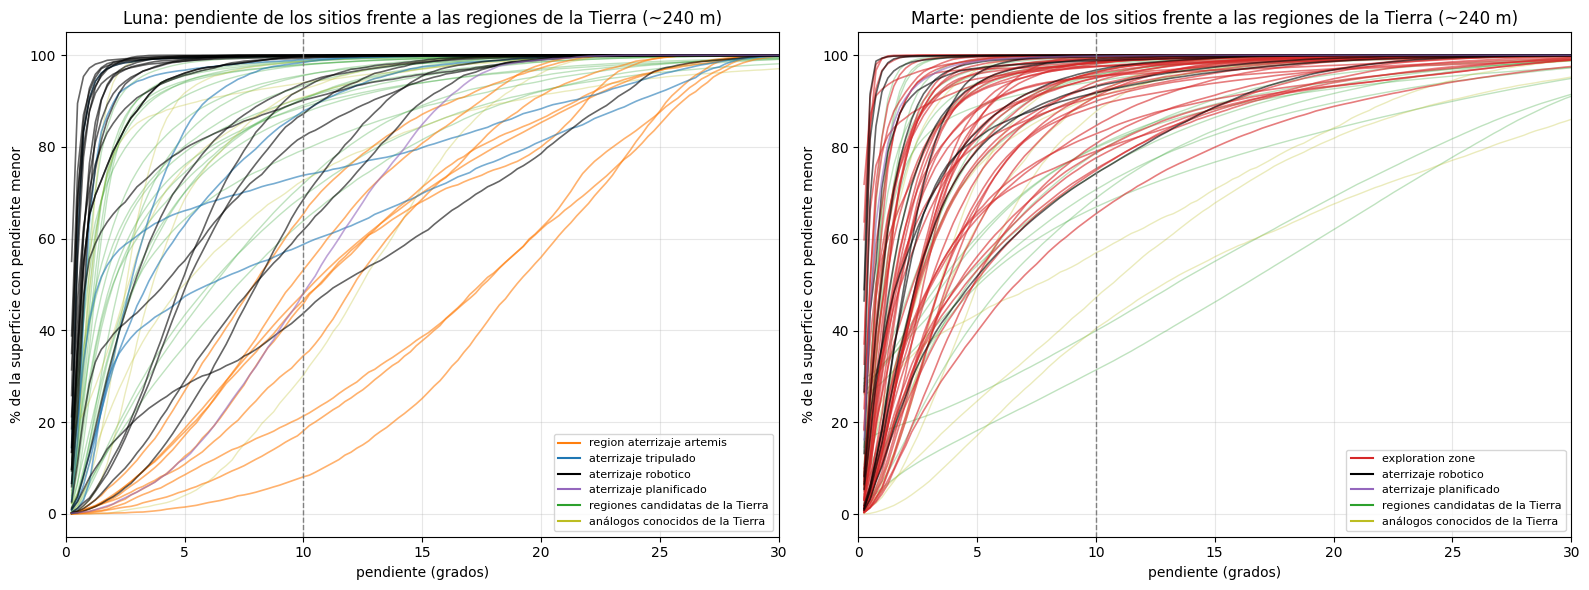

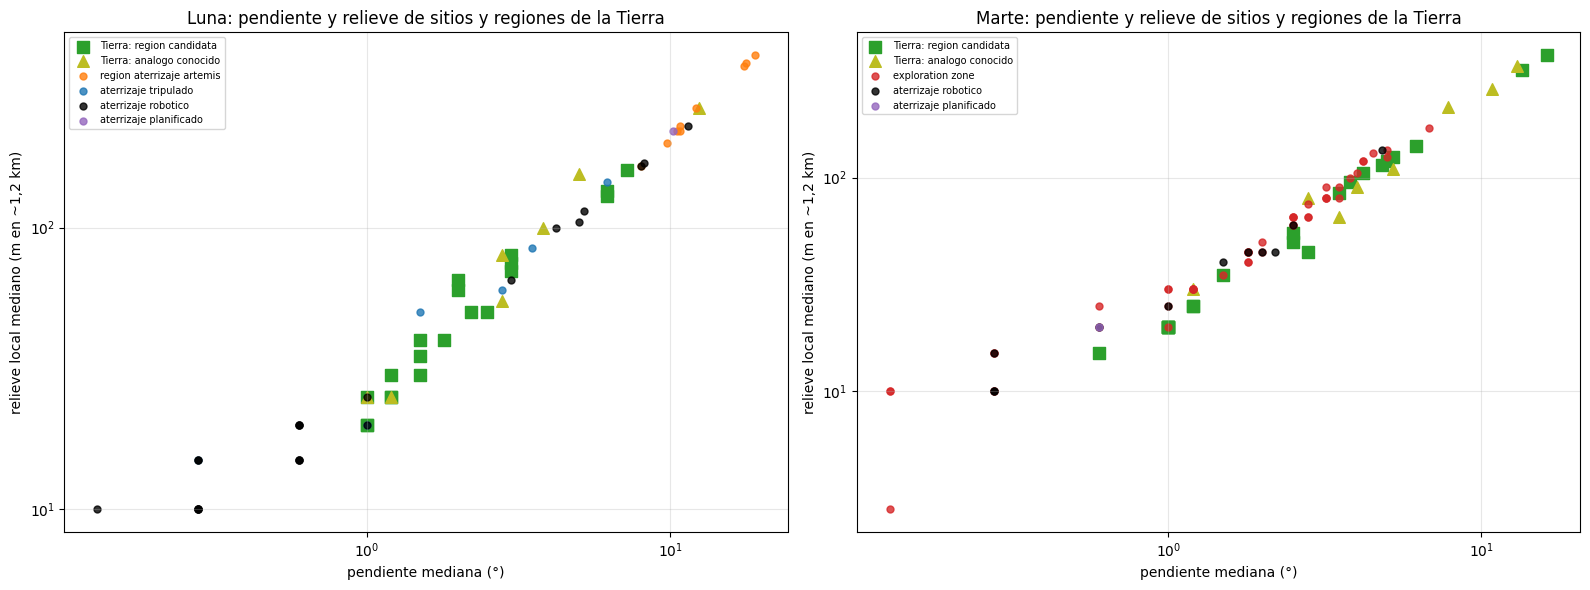

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
x = BINS[1:]
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    for t in tierra[tierra.cuerpo == cuerpo].itertuples():
        ax.plot(x, cdf(H_T[t.region_id]) * 100, color="tab:green" if t.tipo_t == "region_candidata" else "tab:olive", alpha=0.3, lw=1)
    colores = {"region_aterrizaje_artemis": "tab:orange", "exploration_zone": "tab:red", "aterrizaje_tripulado": "tab:blue",
               "aterrizaje_robotico": "black", "aterrizaje_planificado": "tab:purple"}
    for tipo, color in colores.items():
        sel = sit[(sit.cuerpo == cuerpo) & (sit.tipo == tipo)]
        for r in sel.itertuples():
            if HIST[r.id].sum():
                ax.plot(x, cdf(HIST[r.id]) * 100, color=color, alpha=0.6, lw=1.2)
        if len(sel):
            ax.plot([], [], color=color, label=tipo.replace("_", " "))
    ax.plot([], [], color="tab:green", label="regiones candidatas de la Tierra")
    ax.plot([], [], color="tab:olive", label="análogos conocidos de la Tierra")
    ax.axvline(10, color="grey", ls="--", lw=1); ax.set_xlim(0, 30); ax.grid(alpha=0.3); ax.legend(fontsize=8)
    ax.set_xlabel("pendiente (grados)"); ax.set_ylabel("% de la superficie con pendiente menor")
    ax.set_title(f"{cuerpo.capitalize()}: pendiente de los sitios frente a las regiones de la Tierra (~240 m)")
plt.tight_layout(); plt.show()

# Mapa pendiente–relieve: sitios frente a la Tierra
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, cuerpo in zip(axes, ["luna", "marte"]):
    t = tierra[tierra.cuerpo == cuerpo]
    for tipo_t, mk, c in (("region_candidata", "s", "tab:green"), ("analogo_conocido", "^", "tab:olive")):
        u = t[t.tipo_t == tipo_t]; ax.scatter(u.mediana, u.relieve_mediana, marker=mk, c=c, s=70, label=f"Tierra: {tipo_t.replace('_', ' ')}")
    for tipo, color in colores.items():
        u = sit[(sit.cuerpo == cuerpo) & (sit.tipo == tipo)]
        if len(u): ax.scatter(u.mediana, u.relieve_mediana, c=color, s=25, alpha=0.8, label=tipo.replace("_", " "))
    ax.set_xscale("symlog", linthresh=1); ax.set_yscale("symlog", linthresh=10)
    ax.set_xlabel("pendiente mediana (°)"); ax.set_ylabel("relieve local mediano (m en ~1,2 km)"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    ax.set_title(f"{cuerpo.capitalize()}: pendiente y relieve de sitios y regiones de la Tierra")
plt.tight_layout(); plt.show()

## 7. Capa para la web y registro

In [21]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else float(v)
    if isinstance(v, np.integer): return int(v)
    return v

salida = {"version": VERSION, "unidades": {"pendiente": "grados", "relieve": "m (máximo − mínimo en ~1,2 km)",
                                            "distancia": "media de KS de pendiente y KS de relieve, 0–1, menor es más parecido"},
          "umbral_parecido": UMBRAL_PARECIDO,
          "sitios": {r["id"]: {**{k: limpio(v) for k, v in r.items() if k != "id"},
                               "top5_tierra": [{k: limpio(v) for k, v in p.items() if k != "sitio_id"}
                                               for p in top[top.sitio_id == r["id"]].to_dict("records")]}
                     for r in sit.to_dict("records")},
          "nota": "unir con 06_web/sitios_v0/sitios.geojson por id y con topografia_v1/topografia.json por region_id"}
json.dump(salida, open(f"{WEB}/topografia_sitios.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2, allow_nan=False)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["topografia_sitios"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/topografia_sitios.json"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
registro = {"version": VERSION, "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
            "datos": {"luna_polar": f"NASA LRO LOLA {PRODUCTO_POLAR} (PDS): {URL_P}", "luna": f"NASA LRO LOLA LDEM_128 (PDS): {URL_C}",
                      "marte": f"USGS HRSC–MOLA Blended DEM Global 200 m v2 (Fergason, Hare y Laura, 2018): {URL_MARTE}",
                      "tierra": "histogramas a ~240 m de topografia_v1 (NASA ASTER GDEM v3), regiones completas y análogos conocidos"},
            "orientacion_polar": {"elegida": list(ORIENT), "correlacion": round(float(pruebas[ORIENT]), 3)},
            "parametros": {"radio_luna_km": RADIO_LUNA_KM, "radio_marte_km": RADIO_MARTE_KM, "umbral_parecido": UMBRAL_PARECIDO,
                           "lado_relieve_m": LADO_RELIEVE_M, "distancia": "media(KS pendiente, KS relieve)"},
            "conteo": {"sitios": int(len(sit)), "regiones_tierra": int(len(tierra))},
            "limitaciones": ["solo forma del terreno (pendiente y relieve): no incluye clima, materiales ni iluminación",
                             "la ventana del relieve es de 5 píxeles (~1,2 km) en Luna y Tierra y de 7 píxeles (~1,4 km) en Marte",
                             "Marte a 200 m y Tierra/Luna a ~240 m: escalas parecidas pero no idénticas",
                             "las Exploration Zones se miden en un radio de 25 km alrededor de su centro, no en sus 100 km"]}
json.dump(registro, open(f"{RES}/registro_{VERSION}.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print("topografia_sitios.json:", f"{os.path.getsize(f'{WEB}/topografia_sitios.json') / 1e3:.0f} KB", "| capas:", list(entrada["capas"]))

topografia_sitios.json: 282 KB | capas: ['cuevas', 'topografia', 'sitios', 'topografia_sitios']


## 8. Conclusiones
# Topografía v1: cierre (26 oct 2026)

Notebooks: `topografia_v1.ipynb` (Tierra) y `topografia_sitios_v1.ipynb` (sitios de la Luna y Marte frente a la Tierra).

## Qué cambió respecto a v0
- Tierra medida entera: 1053/1053 teselas ASTER (Argelia 557). Por tandas de 40 min, una tesela cada vez; ninguna caída de RAM.
- Análogos conocidos de la ficha medidos con el mismo método (círculo de 10 km): 7 de la Luna y 8 de Marte.
- Segunda medida: relieve local (máximo − mínimo en ~1,2 km sobre la rejilla de ~240 m).
- Comparación por sitio: distancia combinada = media de KS de pendiente y KS de relieve; «parecido» si ≤ 0,2.

## Resultados
- Regiones Artemis: 6/9 con parecido (v0: 4/9). Mejores: de Gerlache Rim 2 ↔ Mauna Kea 0,096; Slater Plain ↔ Irán 0,107; Haworth ↔ Irán 0,178; Mons Mouton ↔ Mauna Kea 0,180; Mons Mouton Plateau ↔ Irán 0,200 y Nobile Rim 2 ↔ Mauna Kea 0,200 (en el límite).
- Sin análogo: Peak Near Cabeus B (0,48), Nobile Rim 1 (0,385), Malapert (0,37). Son los más abruptos (mediana 17–19°, relieve 375–410 m).
- Apollo 5/6 (Apollo 14 ↔ Kīlauea 0,081; Apollo 11 ↔ La Meca 0,084; Apollo 16 ↔ Islandia 0,085; Apollo 17 ↔ Askja 0,158). Robóticos Luna 14/22. Marte 52/59.
- Sin pareja en la Tierra: los mares lunares más llanos (Apollo 12, Luna 13 y 17, Surveyor 1 y 3, Chang'e 3, 5 y 6) y las llanuras más lisas de Marte (Viking 1, InSight, EZ Viking, Zephyria, Arcadia ×2, Erebus). Su relieve mediano es de 5–15 m; ninguna región de la Tierra baja de 15–20 m, en parte por el ruido de ASTER.
- Validación con análogos conocidos: 13 de 15 se parecen al menos a un sitio real. Qaidam ↔ Copernicus Crater 0,062 (13 sitios); Atacama ↔ Jezero 0,068 (12); Lanzarote (17); Haughton (9); Kīlauea ↔ Apollo 14 0,081; Mauna Kea ↔ 4 sitios. No encajan Axel Heiberg ni McMurdo (demasiado abruptos), que son análogos de clima o biología, no de relieve.

## Archivos
- 04_resultados/topografia_v1/topografia_regiones_v1.csv
- 04_resultados/topografia_sitios_v1/: topografia_sitios_v1.csv, similitud_sitio_tierra.csv, analogos_conocidos_vs_sitios.csv
- 06_web/topografia_v1/topografia.json y 06_web/topografia_sitios_v1/topografia_sitios.json (registradas en el manifest)
- Bibliografía actualizada: ASTER v1, LOLA LDEM_75S_240M y HRSC–MOLA 200 m.

## Pendiente
- Clima tras el miércoles 28 oct (datos oficiales del reto).